# Analisi di Wikipedia: risultati

Questo notebook riassume i risultati del progetto, calcolati con Apache Spark in locale sul dataset completo (153.232 righe, circa 1 GB):

1. **Qualità dei dati**: duplicati, testi vuoti e testi con più categorie.
2. **Analisi esplorativa** per categoria: numero di articoli, lunghezza dei testi, articoli più lunghi e più corti.
3. **Parole caratteristiche e nuvole di parole** di ogni categoria.
4. **Insights** sui contenuti e sulle tendenze linguistiche.
5. **Classificatore automatico**: confronto dei modelli e valutazione sul test set.

Le sezioni 1–4 vengono calcolate dal vivo (circa 3 minuti). La sezione 5 legge i risultati prodotti da `python train.py --confronto-duplicati`, che va eseguito prima: l'addestramento richiede molto più tempo.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from wikipedia import analysis, wordclouds
from wikipedia.data import clean_dataset, download_dataset, duplication_by_category, quality_report, read_dataset
from wikipedia.spark import cache, get_spark
from wikipedia.text import tokenize

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 90
BLUE, GREY = "#1f4e79", "#b0b0b0"
REPORTS = ROOT / "reports"

spark = get_spark("wikipedia-notebook")
raw = read_dataset(spark, download_dataset(ROOT / "data" / "wikipedia.csv"))
raw.limit(3).toPandas()

,title,summary,documents,categoria
0,economics,economics () is a social science that studies ...,economics () is a social science that studies ...,economics
1,index of economics articles,this aims to be a complete article list of eco...,this aims to be a complete article list of eco...,economics
2,cryptoeconomics,cryptoeconomics is an evolving economic paradi...,cryptoeconomics is an evolving economic paradi...,economics


## 1. Qualità dei dati

Il CSV viene letto direttamente da Spark (`spark.read.csv` con `multiLine` ed `escape`, perché i testi contengono a capo e virgolette), senza passare da pandas.

In [2]:
report = quality_report(raw)
pd.Series(report, name="valore").to_frame()

,valore
righe,153232
righe_uniche,75986
testi_vuoti,463
testi_con_piu_categorie,1192
righe_con_testi_ambigui,2435


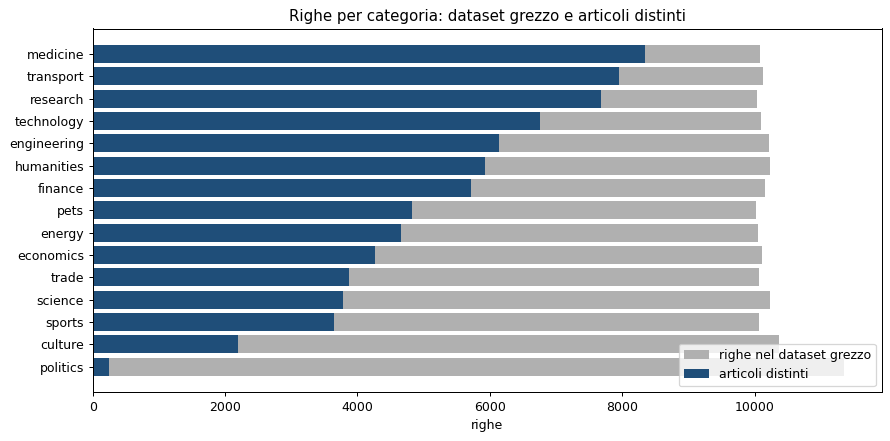

,righe,righe_uniche,quota_duplicati
categoria,,,
politics,11358,243,0.98
culture,10372,2188,0.79
sports,10068,3642,0.64
science,10236,3779,0.63
trade,10068,3877,0.61
economics,10110,4263,0.58
energy,10046,4652,0.54
pets,10023,4827,0.52
finance,10157,5714,0.44


In [3]:
duplication = duplication_by_category(raw).toPandas().set_index("categoria").sort_values("righe_uniche")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(duplication.index, duplication["righe"], color=GREY, label="righe nel dataset grezzo")
ax.barh(duplication.index, duplication["righe_uniche"], color=BLUE, label="articoli distinti")
ax.set_xlabel("righe")
ax.set_title("Righe per categoria: dataset grezzo e articoli distinti")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
duplication.sort_values("quota_duplicati", ascending=False)

- **Metà del dataset è composta da duplicati esatti**: 153.232 righe, ma solo 75.986 distinte.
- Il dataset grezzo sembra **bilanciato** (circa 10.000 righe per categoria), ma è un effetto dei duplicati. In realtà le categorie sono molto sbilanciate: `politics` ha solo **243 articoli distinti** (il 98% delle sue righe è duplicato), `medicine` ne ha 8.351.
- 463 articoli hanno il testo vuoto e 1.192 testi compaiono identici con categorie diverse.

La pulizia (`clean_dataset`) rimuove duplicati e testi vuoti. Esclude anche i testi con più categorie, che non hanno un'etichetta univoca, e tiene un solo articolo per testo.

> Nel progetto originale il passaggio di "rimozione dei duplicati" teneva *solo* le righe duplicate: tutte le analisi successive erano calcolate su 27.548 righe, con 46 articoli per `politics`.

In [4]:
articles = cache(clean_dataset(raw))
print(f"Articoli dopo la pulizia: {articles.count():,}".replace(",", "."))

Articoli dopo la pulizia: 72.178


## 2. Analisi esplorativa per categoria

In [5]:
stats = analysis.category_stats(articles)
stats

,articoli,quota,parole_media,parole_mediana,parole_min,parole_max,parole_summary_media
categoria,,,,,,,
transport,7820,0.11,453.14,160,10,22150,78.42
medicine,7504,0.10,765.27,442,12,18422,99.80
research,6813,0.09,672.13,454,17,27223,93.55
technology,6605,0.09,857.08,475,2,18144,103.57
engineering,5988,0.08,738.57,353,8,11856,90.64
humanities,5731,0.08,914.51,545,7,23198,86.59
finance,5143,0.07,1276.67,645,3,33479,114.49
pets,4603,0.06,406.49,149,12,13222,72.53
energy,4437,0.06,594.83,306,9,23223,98.74


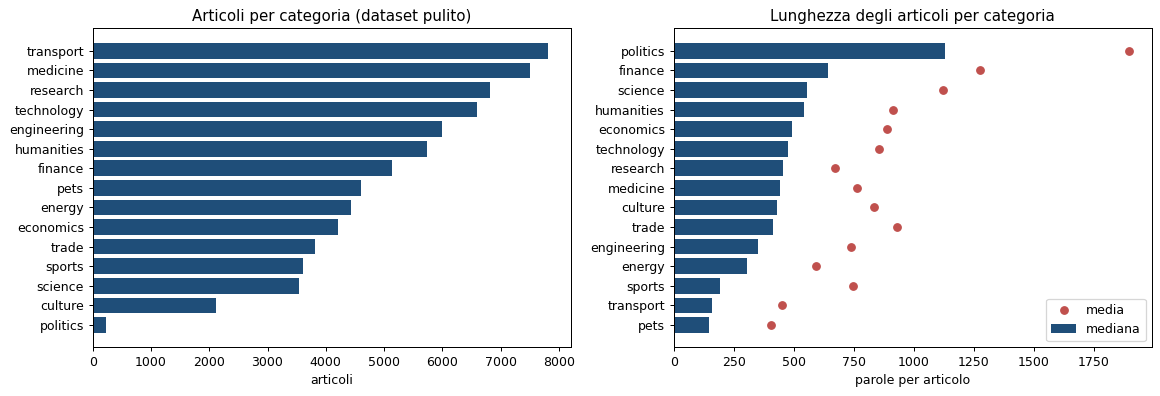

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ordered = stats.sort_values("articoli")
axes[0].barh(ordered.index, ordered["articoli"], color=BLUE)
axes[0].set_xlabel("articoli")
axes[0].set_title("Articoli per categoria (dataset pulito)")
ordered = stats.sort_values("parole_mediana")
axes[1].barh(ordered.index, ordered["parole_mediana"], color=BLUE, label="mediana")
axes[1].scatter(ordered["parole_media"], ordered.index, color="#c0504d", zorder=3, label="media")
axes[1].set_xlabel("parole per articolo")
axes[1].set_title("Lunghezza degli articoli per categoria")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

- In media un articolo ha circa 780 parole, ma la distribuzione è molto asimmetrica: la mediana è circa 400, e pochi articoli molto lunghi (fino a oltre 33.000 parole) alzano la media. Per questo si riportano sia media sia mediana.
- `politics` ha gli articoli più lunghi (mediana di oltre 1.100 parole), `pets` e `transport` i più brevi (circa 150–160).

Articolo più lungo e più corto di ogni categoria:

In [7]:
analysis.extreme_articles(articles)

,title_piu_lungo,parole_piu_lungo,title_piu_corto,parole_piu_corto
categoria,,,,
culture,sanskrit,15538,judenbüchel,11
economics,john von neumann,24022,stéphane just,10
energy,radiation effects from the fukushima daiichi n...,23223,n-ergie,9
engineering,george w. romney,11856,karpfenteich,8
finance,king julian,33479,companies listed on the new york stock exchange,3
humanities,finn abernathy,23198,marius vazeilles,7
medicine,canada convoy protest,18422,hospital pirovano,12
pets,dingo,13222,devario anomalus,12
politics,timeline of 1960s counterculture,20140,electoral history of pauline hanson,11


Gli articoli più corti hanno poche parole e spesso non sono veri articoli. Alcuni sono pagine di servizio, come `wikipedia:wikiproject council/proposals/android` in `technology`, altri sono elenchi, come `companies listed on the new york stock exchange` in `finance`.

## 3. Parole caratteristiche e nuvole di parole

Le parole più frequenti (dopo la rimozione delle stopword) sono simili in molte categorie. Per ogni categoria si calcolano quindi le **parole caratteristiche**, con il punteggio

$$\text{score} = \text{conteggio nella categoria} \times \log\frac{\text{frequenza relativa nella categoria}}{\text{frequenza relativa complessiva}}$$

Il punteggio è alto per le parole frequenti nella categoria e relativamente rare nelle altre, e vale 0 per una parola distribuita in modo uniforme.

In [8]:
tokens = cache(tokenize(articles, "documents").select("categoria", "tokens"))
counts = cache(analysis.word_counts(tokens))
top = analysis.top_words(counts, n=10)
distinctive = analysis.distinctive_words(counts, n=100)
pd.DataFrame({
    "più frequenti": top.groupby("categoria")["word"].apply(", ".join),
    "più caratteristiche": distinctive[distinctive["rank"] <= 10].groupby("categoria")["word"].apply(", ".join),
})

,più frequenti,più caratteristiche
categoria,,
culture,"dance, cemetery, jewish, film, cultural, th, p...","dance, cemetery, jewish, rabbi, film, israel, ..."
economics,"university, economics, economic, party, resear...","economics, economic, university, party, social..."
energy,"power, energy, station, plant, company, electr...","power, energy, plant, electricity, mw, station..."
engineering,"water, river, dresden, german, air, engineerin...","water, dresden, heat, engineering, german, riv..."
finance,"company, million, building, series, announced,...","company, million, acquired, bank, billion, bus..."
humanities,"university, history, archaeology, work, societ...","archaeology, archaeological, anthropology, mus..."
medicine,"hospital, health, medical, university, medicin...","hospital, health, medical, medicine, care, uni..."
pets,"species, fish, dog, breed, references, greyhou...","species, fish, dog, breed, greyhound, dogs, st..."
politics,"political, party, public, government, state, s...","political, party, policy, politics, immigratio..."


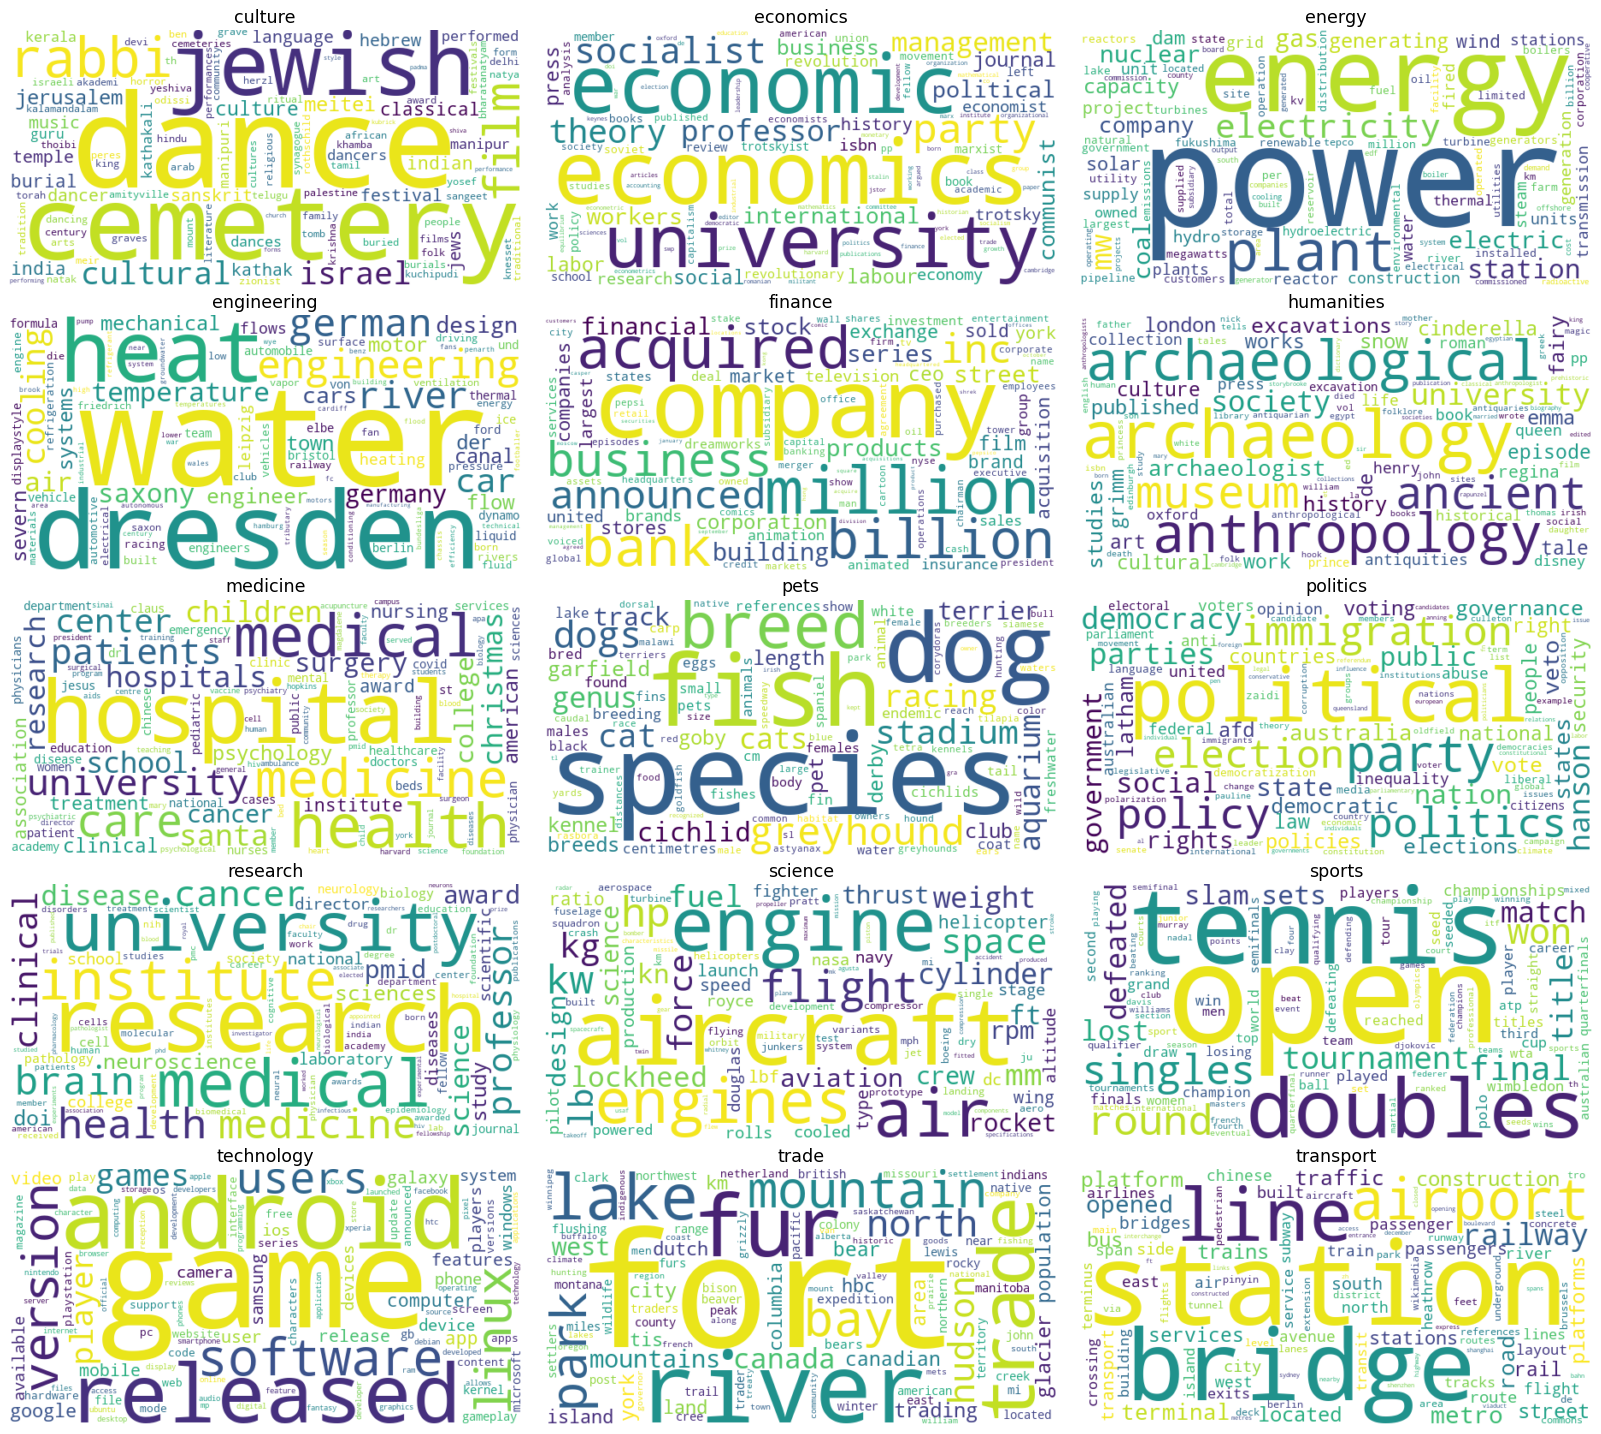

In [9]:
fig = wordclouds.wordcloud_grid(distinctive)
plt.show()

## 4. Insights

**Le categorie riflettono il modo in cui è stato costruito il dataset più che il significato del loro nome.** Le parole caratteristiche mostrano che:
- `science` è dominata da articoli di aviazione e motori (*aircraft*, *engine*, *flight*, *lockheed*);
- `trade` da storia del commercio di pellicce in Nord America (*fort*, *fur*, *river*, *hudson*, *bay*);
- `engineering` da articoli sulla Germania e su Dresda (*dresden*, *saxony*, *german*);
- `sports` quasi solo da tennis (*tennis*, *open*, *doubles*, *singles*);
- `pets` da pesci d'acquario e cani (*species*, *fish*, *dog*, *breed*, *cichlid*).

Per Wikimedia questo significa che le categorie del dataset non sono un campione rappresentativo dei rispettivi temi. Un classificatore addestrato su questi dati imparerà questi sotto-argomenti, e potrebbe sbagliare su articoli dello stesso tema ma di altri sotto-argomenti (per esempio un articolo di calcio per `sports`).

**Densità degli articoli.** Le categorie più rappresentate sono `transport`, `medicine` e `research` (9–11% ciascuna); `culture` (3%) e soprattutto `politics` (0,3%) sono le meno coperte. Sono le categorie su cui conviene concentrare gli sforzi di raccolta di nuovi articoli.

**Tendenze linguistiche.** Indicatori calcolati per articolo e poi mediati per categoria:
- *ricchezza lessicale*: parole distinte / parole totali, sui primi 300 termini di ogni articolo, per non confrontare solo le lunghezze;
- *lunghezza media delle parole*, in lettere.

In [10]:
analysis.lexical_stats(tokens)

,ricchezza_lessicale,lunghezza_media_parole,articoli_considerati
categoria,,,
humanities,0.72,6.77,5563
pets,0.71,6.53,2865
culture,0.71,6.70,2014
engineering,0.69,6.72,4984
research,0.69,7.15,6520
trade,0.69,6.52,3386
economics,0.68,7.05,4036
medicine,0.68,6.93,7146
sports,0.68,6.27,2985


Le differenze sono contenute. Gli articoli di `humanities`, `pets` e `culture` usano un lessico più vario; quelli di `energy` e `transport` sono più ripetitivi, con molti termini tecnici ricorrenti come *power*, *station*, *line*. Le parole sono più lunghe in `politics`, `research` ed `economics`, con un linguaggio più astratto e tecnico, e più corte in `sports`.

## 5. Classificatore automatico

Pipeline Spark ML: `RegexTokenizer → StopWordsRemover → CountVectorizer (50.000 parole) → IDF → classificatore`. Il testo usato è `documents`, che contiene già il `summary` come primo paragrafo.

- Lo split train/test (80/20) è **stratificato**, così ogni categoria è rappresentata nella stessa proporzione in entrambi gli insiemi.
- I modelli vengono confrontati su un validation set ricavato dal training set.
- Il migliore per **F1 macro** viene valutato una sola volta sul test set. L'F1 macro è la media non pesata tra le categorie, quindi conta anche le categorie piccole come `politics`.

I risultati seguenti sono quelli salvati da `train.py`.

In [11]:
results = json.loads((REPORTS / "risultati_classificatore.json").read_text(encoding="utf-8"))
pd.read_csv(REPORTS / "confronto_modelli.csv", index_col=0)

,accuratezza,f1_macro,f1_pesato,secondi
modello,,,,
Regressione logistica (regParam=0.01),0.91,0.89,0.91,152.98
"Regressione logistica (regParam=0.01, pesi per classe)",0.91,0.89,0.91,193.56
Regressione logistica (regParam=0.001),0.90,0.89,0.90,170.12
Regressione logistica (regParam=0.1),0.89,0.87,0.89,188.00
Regressione logistica con standardizzazione (regParam=0.01),0.86,0.84,0.86,210.88
Naive Bayes,0.85,0.82,0.85,3.30
Random forest (2.000 parole),0.71,0.63,0.70,131.28


In [12]:
print(f"Modello scelto: {results['modello']}")
pd.DataFrame({
    "test set (dati puliti)": results["test"],
    "come nel progetto originale (con duplicati)": {k: v for k, v in results["con_duplicati"].items()
                                                    if k != "quota_test_presente_nel_training"},
}).T

Modello scelto: Regressione logistica (regParam=0.01)


,accuratezza,f1_macro,f1_pesato
test set (dati puliti),0.91,0.89,0.91
come nel progetto originale (con duplicati),0.94,0.94,0.94


In [13]:
print(f"Quota del test set già presente nel training set con i duplicati: "
      f"{results['con_duplicati']['quota_test_presente_nel_training']:.0%}")
report = pd.read_csv(REPORTS / "metriche_per_categoria.csv", index_col=0)
report.sort_values("f1-score")

Quota del test set già presente nel training set con i duplicati: 65%


,precision,recall,f1-score,articoli
politics,0.70,0.49,0.57,47.00
medicine,0.85,0.81,0.83,1501.00
research,0.82,0.88,0.85,1363.00
finance,0.87,0.85,0.86,1029.00
culture,0.90,0.84,0.87,425.00
science,0.92,0.83,0.87,710.00
engineering,0.86,0.90,0.88,1198.00
trade,0.93,0.89,0.91,763.00
economics,0.93,0.92,0.92,842.00
humanities,0.92,0.93,0.93,1146.00


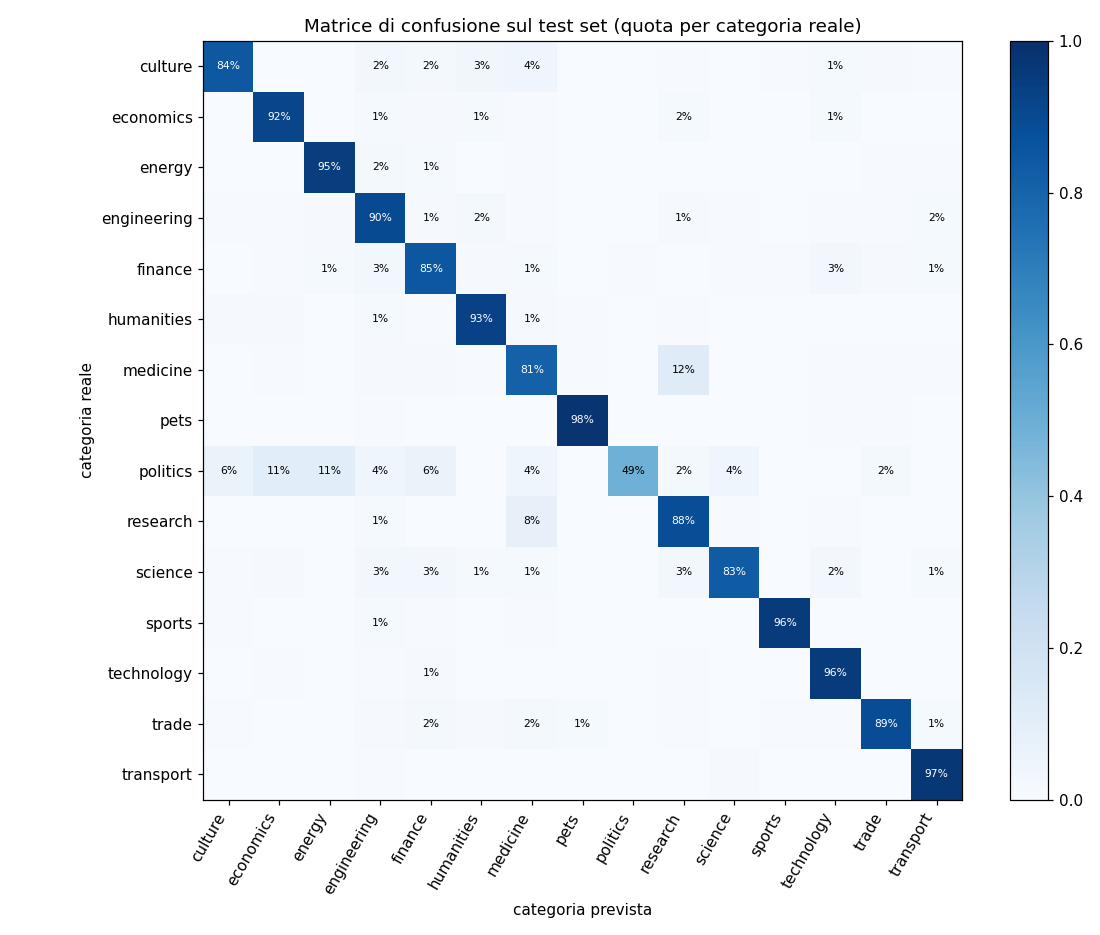

In [14]:
display(Image(filename=str(ROOT / "images" / "matrice_confusione.png")))

In [15]:
pd.read_csv(REPORTS / "parole_classificatore.csv", index_col=0).apply(", ".join, axis=1).to_frame("parole con il peso più alto")

,parole con il peso più alto
transport,"metro, located, opened, chongqing, nanjing, di..."
medicine,"hospital, psychological, hospitals, physician,..."
research,"neuroscientist, pathologist, neurologist, epid..."
technology,"smartphone, ios, computer, programmer, website..."
engineering,"saxony, flows, germany, footballer, born, thur..."
humanities,"archaeologist, antiquarian, anthropologist, ar..."
finance,"moscow, stock, canary, fortune, filmography, i..."
pets,"cichlid, endemic, genus, goby, length, species..."
energy,"fired, power, pakistani, mw, cyclassics, owned..."
economics,"trotskyist, economist, historian, revolutionar..."


In [16]:
spark.stop()